In [11]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [12]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")


beta_uni = 0.255413, beta_SG = 0.549306


In [13]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/nb_star_{graph_type}_{coup_type}_d{d}_N*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique())
df

betas: [0.23 0.24 0.25 0.26 0.27] 
sizes: [100000   1000  10000]


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,time,mean_nb_star,std_nb_star
0,0.23,F_beta_Glauber,False,full_star,50,100000000,100000,50,1,99999.76,0.427083
1,0.23,F_beta_Glauber,False,full_star,50,100000000,100000,50,2,99999.40,0.632456
2,0.23,F_beta_Glauber,False,full_star,50,100000000,100000,50,3,99999.08,0.770454
3,0.23,F_beta_Glauber,False,full_star,50,100000000,100000,50,4,99998.74,0.934024
4,0.23,F_beta_Glauber,False,full_star,50,100000000,100000,50,5,99998.36,1.034601
...,...,...,...,...,...,...,...,...,...,...,...
12550,0.27,F_beta_Glauber,False,full_star,50,100000000,10000,0,92889787,2829.68,311.154395
12551,0.27,F_beta_Glauber,False,full_star,50,100000000,10000,0,94618482,2830.78,279.691065
12552,0.27,F_beta_Glauber,False,full_star,50,100000000,10000,0,96379348,2854.42,312.267519
12553,0.27,F_beta_Glauber,False,full_star,50,100000000,10000,0,98172984,2862.78,287.290883


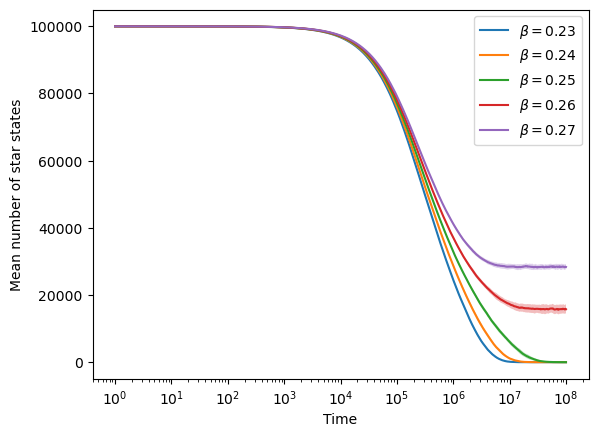

In [19]:
fig, ax = plt.subplots()

N_plotted = 100000
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=rf'$\beta={beta:.2f}$')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

In [15]:
fig.savefig(f'../results/perm/nb_star_evol_{graph_type}_{coup_type}_d{d}_N{N_plotted}.png', dpi=500, bbox_inches='tight')

/tmp/ipykernel_82199/4083130967.py:20: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


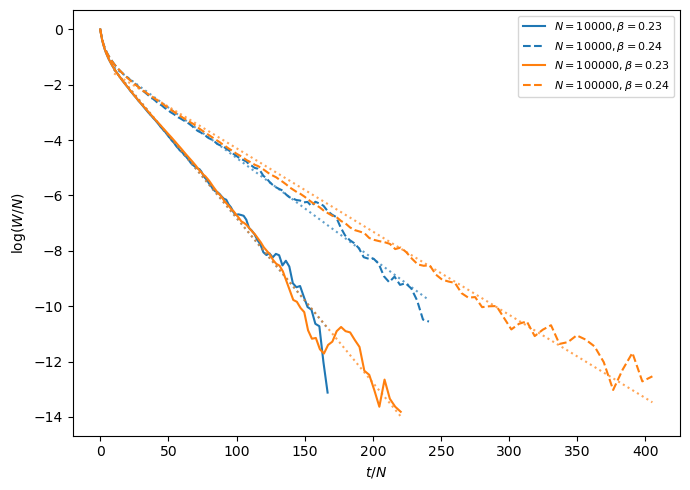

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))

if graph_type == 'ER' and coup_type == 'ising':
    beta_list = [0.23,0.24]
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_list = [0.30, 0.32]
else:
    beta_list = df['beta'].unique()

N_list = [10000, 100000]
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i, N in enumerate(N_list):
    color = prop_cycle[i % len(prop_cycle)]
    for beta in beta_list:
        csv_path = f"../results/tmp/nb_star_{graph_type}_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

        linestyle = '-' if beta == beta_list[0] else '--'
        ax.plot(t_over_N, log_W_over_N, color=color, linestyle=linestyle,
                label=rf'$N={N}, \beta={beta:.2f}$')

        mask = (t_over_N > 10) & np.isfinite(log_W_over_N)
        if mask.sum() > 2:
            slope, intercept, r, _, _ = linregress(t_over_N[mask], log_W_over_N[mask])
            C = -slope
            ax.plot(t_over_N[mask], intercept + slope * t_over_N[mask],
                    ':', color=color, alpha=0.7)#, label=rf'$C={C:.3f}$')

ax.set_xlabel(r'$t/N$')
ax.set_ylabel(r'$\log(W/N)$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
fig.savefig(f'../results/perm/nb_star_scaling_{graph_type}_{coup_type}_d{d}.png', dpi=500, bbox_inches='tight')